# 01. EDA — 학습 데이터만으로 데이터 이해하기

**원칙**: 데이터를 먼저 시간순으로 나누고(앞 75% 학습 / 뒤 25% 평가), 평가 데이터는 잠가 둔다.
이 노트북은 `load_train()`만 쓴다. 여기서 내린 결정은 `PROTOCOL.md`에 정리한다.

확인할 질문
1. 불량은 얼마나 드문가 → 평가 지표
2. 결측은 얼마나, 어떤 패턴인가 → 제거 / 대체 / 결측 지시자
3. 정보가 없는 센서는 몇 개인가
4. 시간에 따라 무엇이 변하나 → 교차검증 방식, 판정 기준 방식
5. 극단값(센서 오류값)이 있나 → 극단값 처리
6. 중복 센서는 얼마나 되나 → 모델 규제, 해석 방식

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import fisher_exact
from src.data import load_train

sns.set_theme(style="whitegrid")
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

X, y, ts = load_train()
print(f"학습 데이터: {len(X)}행, 센서 {X.shape[1]}개, 기간 {ts.min():%Y-%m-%d} ~ {ts.max():%Y-%m-%d}")

학습 데이터: 1175행, 센서 590개, 기간 2008-07-19 ~ 2008-09-29


## 1. 클래스 비율

fail
pass    1095
fail      80
불량률 6.81%, '전부 정상'으로 찍을 때 정확도 93.19%


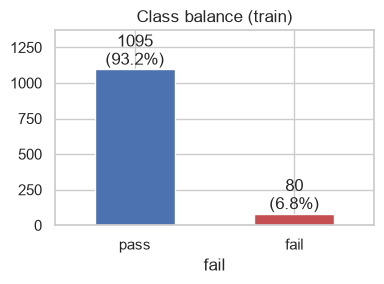

In [2]:
counts = y.value_counts().rename({0: "pass", 1: "fail"})
print(counts.to_string())
print(f"불량률 {y.mean():.2%}, '전부 정상'으로 찍을 때 정확도 {1 - y.mean():.2%}")

fig, ax = plt.subplots(figsize=(4, 3))
counts.plot.bar(ax=ax, color=["#4C72B0", "#C44E52"], rot=0)
for i, v in enumerate(counts):
    ax.text(i, v, f"{v}\n({v / len(y):.1%})", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.25)
ax.set_title("Class balance (train)")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_class_balance.png", dpi=150)

**해석**: 불량 80개(6.8%). 전부 정상이라고 해도 정확도 93%가 나온다.
→ 정확도는 쓰지 않는다. **PR-AUC**(무작위 기준선 = 불량 비율)와 **불량 재현율**을 본다. 학습 시 `class_weight`로 불량 손실을 키운다.

## 2. 결측

In [3]:
miss = X.isna().mean().sort_values(ascending=False)
print(f"전체 셀 결측률 {X.isna().values.mean():.2%}, 결측 있는 센서 {(miss > 0).sum()}개")
pd.Series({f"> {int(t*100)}%": int((miss > t).sum()) for t in [0.05, 0.2, 0.5, 0.8]}, name="센서 수").to_frame()

전체 셀 결측률 4.82%, 결측 있는 센서 442개


,센서 수
> 5%,52
> 20%,52
> 50%,24
> 80%,20


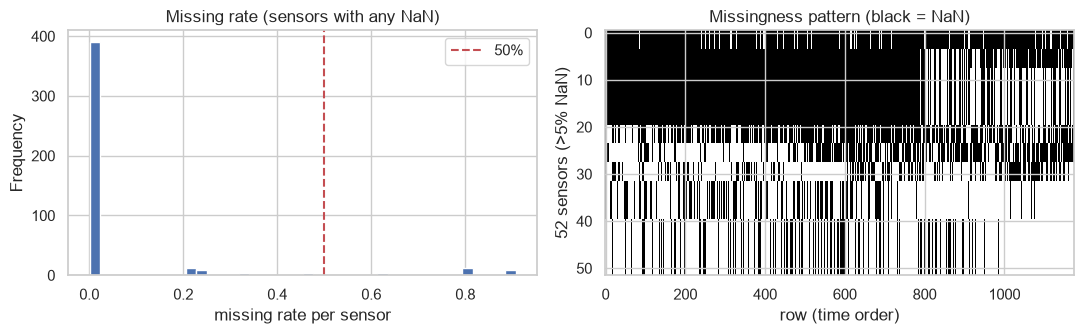

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
miss[miss > 0].plot.hist(bins=40, ax=axes[0], color="#4C72B0")
axes[0].axvline(0.5, color="r", ls="--", label="50%")
axes[0].set_xlabel("missing rate per sensor"); axes[0].set_title("Missing rate (sensors with any NaN)"); axes[0].legend()

top = miss.index[miss > 0.05]
axes[1].imshow(X[top].isna().T.values, aspect="auto", cmap="Greys", interpolation="nearest")
axes[1].set_xlabel("row (time order)"); axes[1].set_ylabel(f"{len(top)} sensors (>5% NaN)")
axes[1].set_title("Missingness pattern (black = NaN)")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_missing.png", dpi=150)

**해석**: 대부분 센서는 거의 안 비었지만, 52개는 5% 넘게 비었고 그중 24개는 절반 넘게 비었다.
오른쪽 그림에서 여러 센서가 **같은 시기에 함께** 비어 있다. 무작위 결측이 아니라 계측 방식이 시기별로 바뀐 것으로 보인다.

결측 여부와 불량의 관계를 확인한다.

In [5]:
rows = []
for c in miss.index[(miss > 0.01) & (miss < 0.99)]:
    is_na = X[c].isna()
    _, p = fisher_exact(pd.crosstab(is_na, y))
    rows.append({"sensor": c, "결측률": miss[c], "p_value": p,
                 "비었을 때 불량률": y[is_na].mean(), "값 있을 때 불량률": y[~is_na].mean()})
na_assoc = pd.DataFrame(rows).sort_values("p_value")
print(f"결측 여부가 불량과 유의하게 연관된 센서 (p<0.01): {(na_assoc.p_value < 0.01).sum()}개")
na_assoc.head(6).round(4)

결측 여부가 불량과 유의하게 연관된 센서 (p<0.01): 8개


,sensor,결측률,p_value,비었을 때 불량률,값 있을 때 불량률
27,sensor_345,0.4664,0.0002,0.0383,0.0941
26,sensor_346,0.4664,0.0002,0.0383,0.0941
25,sensor_073,0.4664,0.0002,0.0383,0.0941
24,sensor_072,0.4664,0.0002,0.0383,0.0941
29,sensor_519,0.3234,0.0012,0.0342,0.0843
31,sensor_247,0.3234,0.0012,0.0342,0.0843


In [6]:
half = len(X) // 2
pd.DataFrame({
    "앞 절반": [X["sensor_072"].isna()[:half].mean(), y[:half].mean()],
    "뒤 절반": [X["sensor_072"].isna()[half:].mean(), y[half:].mean()],
}, index=["sensor_072 결측률", "불량률"]).style.format("{:.1%}")

,앞 절반,뒤 절반
sensor_072 결측률,28.8%,64.5%
불량률,10.7%,2.9%


**해석**: "비었을 때 불량률 3.8%, 값 있을 때 9.4%"로 차이가 크다. 그런데 학습 기간 뒤 절반에서 결측은 **늘고** 불량률은 **줄었다**.
결측이 불량의 원인이라기보다 **시기**를 대신 나타내는 것일 수 있다(교란).

→ 결측 지시자는 넣을지 말지 미리 정하지 않고, **교차검증에서 켜고 끈 경우를 비교**해서 정한다.

## 3. 정보가 없는 센서

In [7]:
nunique = X.nunique(dropna=True)
print(f"값이 하나뿐인 센서: {(nunique <= 1).sum()}개 / {X.shape[1]}")

값이 하나뿐인 센서: 122개 / 590


**해석**: 122개(21%)는 학습 기간 내내 같은 값이다. 정상/불량 구분에 쓸 수 없으므로 제거한다.

## 4. 시간에 따른 변화

,제품 수,불량률
t,,
2008-07-01 00:00:00,63,22.2%
2008-08-01 00:00:00,555,9.2%
2008-09-01 00:00:00,557,2.7%


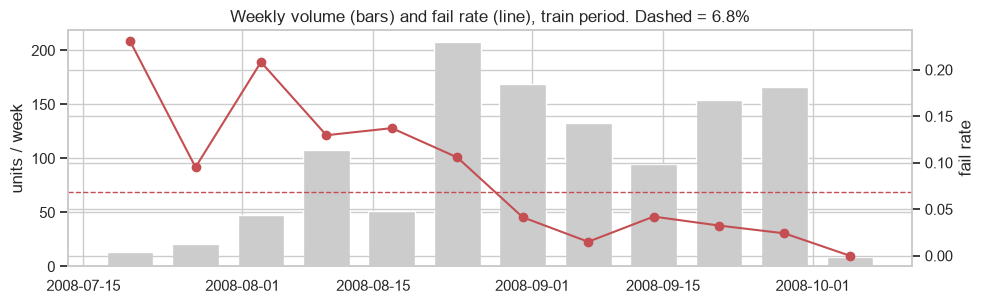

In [8]:
monthly = pd.DataFrame({"t": ts, "fail": y}).set_index("t")["fail"].resample("MS").agg(["count", "mean"])
monthly.columns = ["제품 수", "불량률"]
display(monthly.style.format({"불량률": "{:.1%}"}))

weekly = pd.DataFrame({"t": ts, "fail": y}).set_index("t")["fail"].resample("W").agg(["count", "mean"])
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(weekly.index, weekly["count"], width=5, color="#CCCCCC")
ax2 = ax.twinx()
ax2.plot(weekly.index, weekly["mean"], "o-", color="#C44E52")
ax2.axhline(y.mean(), color="#C44E52", ls="--", lw=1)
ax.set_ylabel("units / week"); ax2.set_ylabel("fail rate")
ax.set_title(f"Weekly volume (bars) and fail rate (line), train period. Dashed = {y.mean():.1%}")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_fail_rate_over_time.png", dpi=150)

**해석**: 학습 기간 안에서도 불량률이 **7월 22% → 8월 9% → 9월 2.7%**로 크게 떨어진다. 공정이 바뀌고 있다.

→ 결정
- 교차검증도 시간순(`TimeSeriesSplit`)으로 한다. 항상 과거로 학습하고 다음 시기로 검증한다.
- 평가 기간(9월 말 이후)도 학습 기간과 분포가 다를 가능성이 크다. 확률값 자체가 시기에 따라 이동할 수 있다는 점을 판정 기준 설계에 반영한다(5번 참고).

## 5. 극단값 (센서 오류값으로 보이는 값)

In [9]:
varying = X.loc[:, nunique > 1]
med = varying.median()
iqr = (varying.quantile(0.75) - varying.quantile(0.25)).replace(0, np.nan)
robust_z = ((varying - med) / iqr).abs()

print(f"보통 범위(중앙값±IQR)의 50배를 넘는 값: {int((robust_z > 50).sum().sum())}칸, 센서 {int((robust_z > 50).any().sum())}개")
examples = robust_z.max().sort_values(ascending=False).index[:5]
pd.DataFrame({
    "중앙값": varying[examples].median(),
    "99% 분위수": varying[examples].quantile(0.99),
    "최댓값": varying[examples].max(),
}).round(4)

보통 범위(중앙값±IQR)의 50배를 넘는 값: 556칸, 센서 74개


,중앙값,99% 분위수,최댓값
sensor_340,0.0498,0.2292,5043.8789
sensor_204,0.1666,0.7539,9997.8983
sensor_067,1.0078,1.5482,7272.8283
sensor_287,0.1396,1.2151,292.2274
sensor_152,0.4725,3.7775,924.3780


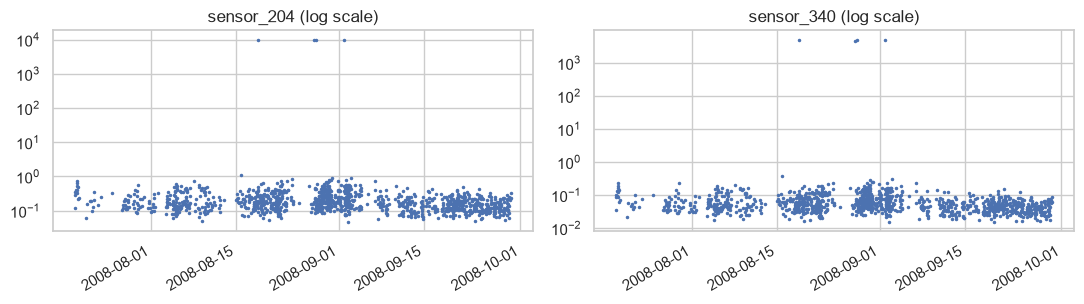

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharex=True)
for ax, c in zip(axes, ["sensor_204", "sensor_340"]):
    ax.plot(ts, X[c], ".", ms=3, color="#4C72B0")
    ax.set_yscale("log"); ax.set_title(f"{c} (log scale)")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIG_DIR / "04_extreme_values.png", dpi=150)

In [11]:
# 학습 기간 안에서 시간에 따라 범위가 바뀌는지: 앞 80%의 범위를 뒤 20%가 벗어나는 비율
cut = int(len(varying) * 0.8)
early, late = varying.iloc[:cut], varying.iloc[cut:]
outside = (late > early.max()) | (late < early.min())
print(f"학습 기간 뒤 20%의 값 중 앞 80% 범위를 벗어난 칸: {outside.values.mean():.2%}, 센서 {int(outside.any().sum())}개")

학습 기간 뒤 20%의 값 중 앞 80% 범위를 벗어난 칸: 0.43%, 센서 135개


**해석**
- `sensor_204`는 보통 0.17 근처인데 **9998**이 찍힌다. `sensor_340`도 보통 0.05인데 **5044**가 있다.
  측정이 아니라 **계측 실패 시 장비가 남기는 오류 코드**로 보인다.
- 74개 센서에 이런 극단값이 있고, 학습 기간 안에서도 뒤쪽 구간이 앞쪽 범위를 벗어나는 경우가 있다.

→ 결정
- 로지스틱 회귀는 `값 × 가중치`를 더하므로 극단값 하나가 점수를 좌우한다.
  학습 데이터의 **0.5% ~ 99.5% 분위수로 자른다(winsorize)**. 최솟값~최댓값으로 자르면 학습 데이터 안의 9998이 그대로 남기 때문에 분위수를 쓴다.
- LightGBM은 대소 비교만 하므로 자르지 않는다.

## 6. 중복 센서

|r| > 0.95인 센서 쌍 305개, 관련 센서 191개


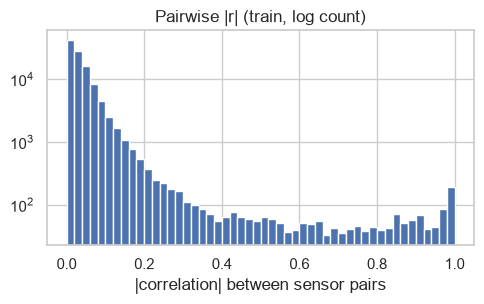

In [12]:
corr = varying.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
print(f"|r| > 0.95인 센서 쌍 {int((upper > 0.95).sum().sum())}개, 관련 센서 {int((upper > 0.95).any().sum())}개")

fig, ax = plt.subplots(figsize=(5, 3.2))
ax.hist(upper.stack().values, bins=50, color="#4C72B0")
ax.set_yscale("log"); ax.set_xlabel("|correlation| between sensor pairs"); ax.set_title("Pairwise |r| (train, log count)")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_correlation.png", dpi=150)

**해석**: 191개 센서가 다른 센서와 거의 같이 움직인다.
→ 로지스틱 회귀는 L2 규제로 가중치가 튀는 것을 막고, SHAP 해석은 상관이 높은 센서를 묶어서 본다.

## 요약: PROTOCOL.md로 넘길 결정

| 발견 (학습 데이터) | 수치 | 결정 |
|---|---|---|
| 불량이 드묾 | 80 / 1175 (6.8%) | PR-AUC, 불량 재현율. 정확도는 참고만. `class_weight` |
| 고결측 센서 | >50%: 24개 | 학습 결측률 50% 초과 센서 제거, 나머지 중앙값 대체(로지스틱) |
| 결측과 불량의 연관 | 8개 센서, 단 시기와 교란 | 결측 지시자 on/off는 교차검증으로 결정 |
| 상수 센서 | 122개 | 제거 |
| 시기 변화 | 월별 불량률 22% → 2.7% | 시간순 교차검증. 판정 기준은 시기 변화에 견디는 방식으로 |
| 센서 오류값 | 74개 센서, 예: 0.17 → 9998 | 로지스틱: 0.5~99.5% 분위수로 자르기. LightGBM: 그대로 |
| 중복 센서 | 191개 | L2 규제, SHAP은 상관 그룹으로 해석 |